# Chapitre 9 - Cours 1 : pannes partielles et réseaux non fiables

Sur une seule machine, un programme correct se comporte de façon **déterministe** : il
marche ou il plante. Dès que plusieurs machines coopèrent à travers un réseau, une partie
du système peut être en panne pendant que le reste fonctionne, et l'on ne sait même pas
toujours si une opération a réussi. Ce notebook pose ce constat et l'examine du point de
vue du réseau. Il couvre les sections *Faults and Partial Failures* et *Unreliable
Networks* (*Network Faults in Practice*, *Fault Detection*, *The Limitations of TCP*) du chapitre 9.

**Plan.**

1. Pannes partielles : la machine seule contre le système distribué.
2. Ce que l'émetteur d'une requête ne peut pas savoir.
3. Les pannes réseau en pratique.
4. Détecter les fautes : les rares signaux explicites, et le délai d'expiration.

5. Les limites de TCP : un accusé de réception n'est pas une réponse.

In [1]:
import socket
import struct
import threading
import time

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
import pandas as pd

from ddia import distsys as ds
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)
from ddia.requirements import plain_log_axis
from ddia.sim import Network, Node
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 4)
rng = np.random.default_rng(0)

## 1. Pannes partielles : la machine seule contre le système distribué (section *Faults and Partial Failures*)

Un ordinateur est conçu pour présenter une **abstraction idéale** : une instruction fait
toujours la même chose, une donnée écrite en mémoire y reste. Quand le matériel défaille
(mémoire corrompue, connecteur desserré), le concepteur préfère que la machine **s'arrête
complètement** (panique du noyau, écran bleu) plutôt que de rendre un résultat faux :
un résultat faux est bien plus difficile à gérer qu'un arrêt. La machine est donc
entièrement fonctionnelle ou entièrement en panne, rarement entre les deux (le cours 4
du chapitre 2 a montré que ce n'est pas tout à fait vrai, mais assez
rarement pour qu'on l'ignore souvent).

Un système distribué n'a pas ce luxe. Certaines de ses parties peuvent être cassées
**de façon imprévisible** pendant que d'autres marchent : c'est une **panne partielle**
(partial failure). Et elle est **non déterministe** : la même opération sur plusieurs
nœuds réussit parfois, échoue parfois, et parfois on ne sait pas si elle a réussi.

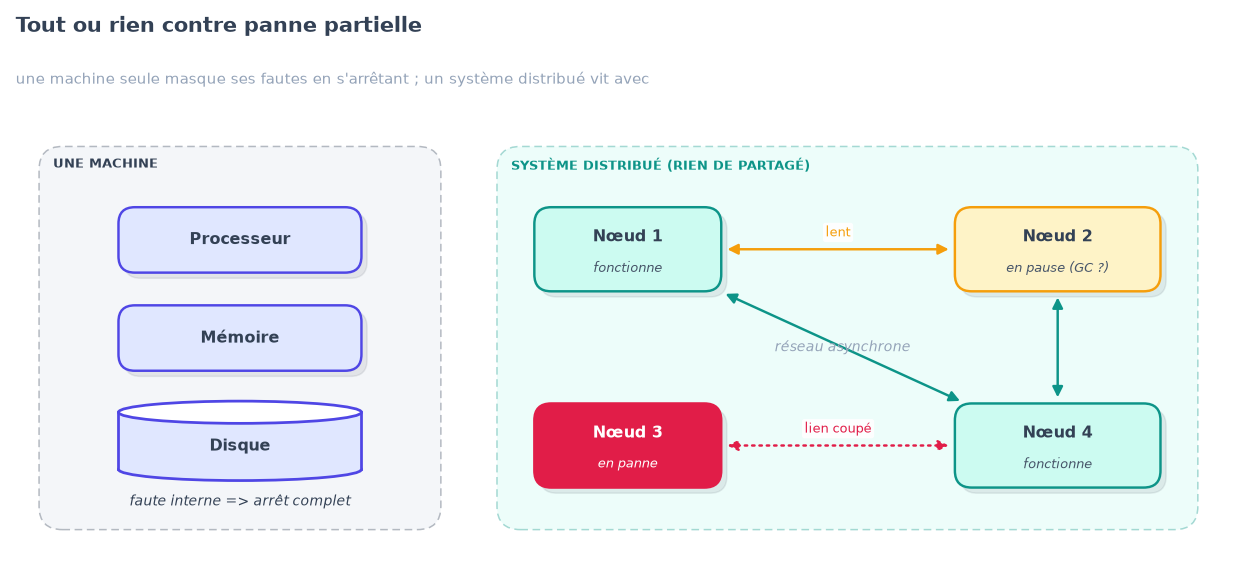

In [2]:
d = Diagram(13, 5.0, title="Tout ou rien contre panne partielle",
            subtitle="une machine seule masque ses fautes en s'arrêtant ; un système distribué vit avec")
d.group(0.3, 0.4, 4.6, 4.5, "une machine", color=SLATE)
d.box("cpu", 2.45, 3.5, "Processeur", color=INDIGO, w=2.6, h=0.7)
d.box("mem", 2.45, 2.45, "Mémoire", color=INDIGO, w=2.6, h=0.7)
d.box("dsk", 2.45, 1.35, "Disque", color=INDIGO, kind="db", w=2.6, h=0.85)
d.note(2.45, 0.7, "faute interne => arrêt complet", color=SLATE)
d.group(5.2, 0.4, 12.7, 4.5, "système distribué (rien de partagé)", color=TEAL)
d.box("n1", 6.6, 3.4, "Nœud 1", sub="fonctionne", color=TEAL, w=2.0)
d.box("n2", 11.2, 3.4, "Nœud 2", sub="en pause (GC ?)", color=AMBER, w=2.2)
d.box("n3", 6.6, 1.3, "Nœud 3", sub="en panne", color=ROSE, w=2.0, filled=True)
d.box("n4", 11.2, 1.3, "Nœud 4", sub="fonctionne", color=TEAL, w=2.2)
d.arrow("n1", "n2", "lent", color=AMBER, both=True)
d.arrow("n1", "n4", "", color=TEAL, both=True)
d.arrow("n3", "n4", "lien coupé", color=ROSE, style="dotted", both=True)
d.arrow("n2", "n4", "", color=TEAL, both=True)
d.note(8.9, 2.35, "réseau asynchrone", color=GRAY)
d.show()

**Un sur un million, c'est tous les jours.** Si une requête doit toucher $n$ nœuds et que
chacun est en faute (transitoire ou durable) avec une probabilité $p$, la probabilité de
rencontrer au moins une faute vaut $1-(1-p)^n \approx np$ pour $np$ petit. À l'échelle d'un
service qui traite des milliards de requêtes par jour, l'événement « improbable » devient
une routine.

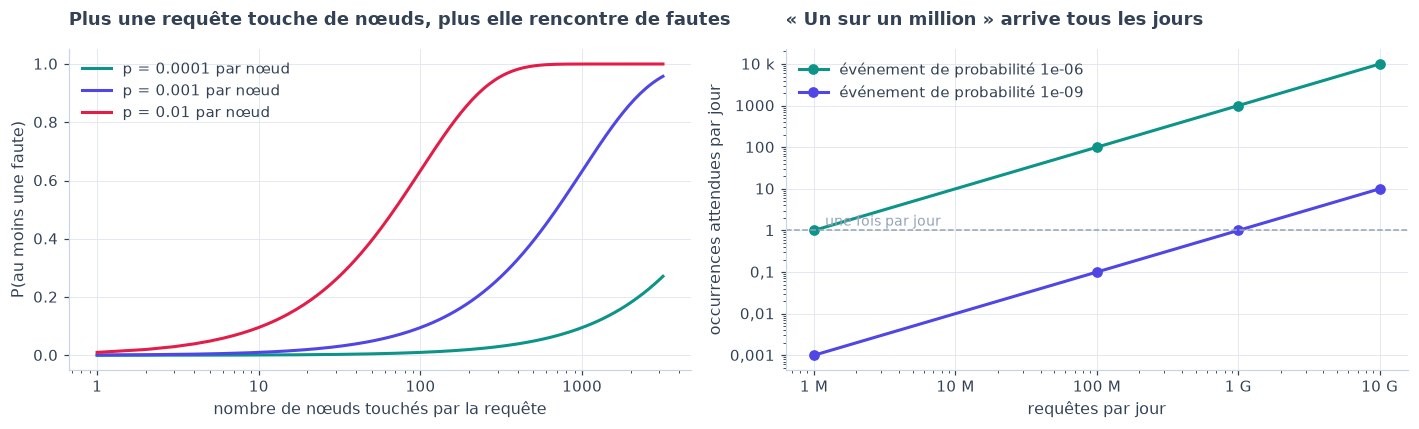

In [3]:
n = np.unique(np.logspace(0, 3.5, 200).astype(int))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
for p, c in [(1e-4, TEAL), (1e-3, INDIGO), (1e-2, ROSE)]:
    ax.plot(n, [ds.partial_failure_probability(p, k) for k in n], color=c, label=f"p = {p:g} par nœud")
ax.set_xscale("log"); plain_log_axis(ax, "x")
ax.set_xlabel("nombre de nœuds touchés par la requête")
ax.set_ylabel("P(au moins une faute)")
ax.set_title("Plus une requête touche de nœuds, plus elle rencontre de fautes")
ax.legend()
ax = axes[1]
volumes = np.array([1e6, 1e8, 1e9, 1e10])
for p, c in [(1e-6, TEAL), (1e-9, INDIGO)]:
    ax.plot(volumes, volumes * p, "o-", color=c, label=f"événement de probabilité {p:g}")
ax.axhline(1, color=GRAY, ls="--", lw=1)
ax.text(1.2e6, 1.3, "une fois par jour", color=GRAY, fontsize=9)
ax.set_xscale("log"); ax.set_yscale("log"); plain_log_axis(ax)
ax.set_xlabel("requêtes par jour"); ax.set_ylabel("occurrences attendues par jour")
ax.set_title("« Un sur un million » arrive tous les jours")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

**Le non-déterminisme, mesuré.** Simulons sur `ddia.sim` une opération simple : un
client envoie une requête à un serveur et attend la réponse au plus 4 unités de temps.
Le réseau perd 5 % des messages et a des délais variables ; le serveur met un temps
variable à traiter (et fait parfois une longue pause). Répétons l'expérience avec 2 000
graines : du point de vue du client, il n'y a que deux issues (réponse ou délai
dépassé), mais du point de vue du serveur, la requête a pu être exécutée ou non.

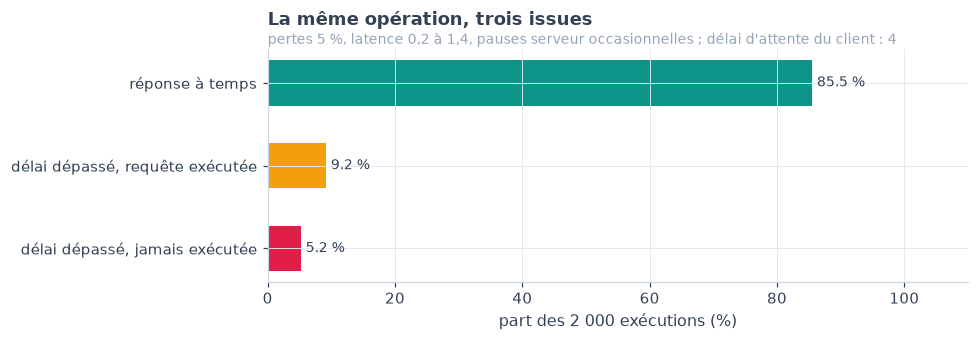

réponse à temps                    1711
délai dépassé, requête exécutée     184
délai dépassé, jamais exécutée      105
Name: count, dtype: int64

In [4]:
class Serveur(Node):
    def __init__(self, name, rng):
        super().__init__(name)
        self.rng, self.executed = rng, 0

    def on_message(self, src, msg):
        lent = self.rng.random() < 0.05                     # pause occasionnelle
        delay = self.rng.uniform(0.1, 0.5) + (self.rng.uniform(3, 8) if lent else 0)
        self.set_timer(delay, self._reply, src)

    def _reply(self, src):
        self.executed += 1
        self.send(src, "réponse")


class Client(Node):
    def __init__(self, name, timeout=4.0):
        super().__init__(name)
        self.timeout, self.answered_at = timeout, None

    def on_start(self):
        self.send("serveur", "requête")

    def on_message(self, src, msg):
        if self.answered_at is None:
            self.answered_at = self.now


def une_requete(seed):
    net = Network(seed=seed, latency=(0.2, 1.4), drop=0.05)
    import random as _r
    s = net.add(Serveur("serveur", _r.Random(seed + 10_000)))
    c = net.add(Client("client"))
    net.run(until=30)
    a_temps = c.answered_at is not None and c.answered_at <= c.timeout
    if a_temps:
        return "réponse à temps"
    return "délai dépassé, requête exécutée" if s.executed else "délai dépassé, jamais exécutée"


issues = pd.Series([une_requete(s) for s in range(2000)]).value_counts()
fig, ax = plt.subplots(figsize=(9, 3.2))
order = ["réponse à temps", "délai dépassé, requête exécutée", "délai dépassé, jamais exécutée"]
vals = issues.reindex(order).fillna(0) / issues.sum() * 100
ax.barh(order[::-1], vals.values[::-1], color=[ROSE, AMBER, TEAL], height=0.55)
annotate_bars(ax, "{:.1f} %")
ax.set_xlim(0, 110); ax.set_xlabel("part des 2 000 exécutions (%)")
ax.set_title("La même opération, trois issues")
subtitle(ax, "pertes 5 %, latence 0,2 à 1,4, pauses serveur occasionnelles ; délai d'attente du client : 4")
plt.tight_layout(); plt.show()
issues

Dans environ une exécution sur dix, le client abandonne. Parmi ces abandons, une bonne
part concerne des requêtes **effectivement exécutées** (la réponse s'est perdue ou est
arrivée trop tard) et l'autre des requêtes **jamais exécutées** (la requête s'est
perdue). Le client ne peut pas les distinguer : c'est toute la difficulté du chapitre.

La contrepartie est précieuse : un système qui **tolère** les pannes partielles peut
être plus fiable que n'importe lequel de ses composants (mise à jour progressive nœud
par nœud, remplacement d'une machine sans interruption). Mais pour tolérer des fautes,
il faut d'abord savoir lesquelles peuvent survenir, même les improbables, et les
provoquer exprès en test : dans un système distribué, la méfiance et le pessimisme
paient.

> **À retenir.** Une machine seule cache ses fautes en s'arrêtant net ; un système
> distribué subit des **pannes partielles**, non déterministes, au point qu'une
> opération peut avoir réussi sans que l'appelant le sache. Ce qui est improbable pour
> une requête devient quotidien à l'échelle d'un service.

## 2. Ce que l'émetteur d'une requête ne peut pas savoir (section *Unreliable Networks*)

Les systèmes du livre sont **sans partage** (shared-nothing) : chaque machine a sa
mémoire et son disque, et le réseau est le **seul** moyen de communiquer (même un stockage partagé, comme un object store, est un service joint par le réseau).
Ce réseau (Internet, Ethernet dans un centre de données) est un **réseau de paquets
asynchrone** : un nœud peut envoyer un paquet à un autre, mais le réseau ne garantit ni
**quand** il arrivera, ni **s'il** arrivera. Quand on envoie une requête et qu'on attend
une réponse, beaucoup de choses peuvent mal tourner :

| ce qui s'est passé | exemple de cause | la requête a-t-elle été exécutée ? |
|---|---|---|
| la requête s'est perdue | câble débranché | non |
| la requête attend dans une file | réseau ou destinataire surchargé | pas encore, peut-être plus tard |
| le nœud distant est tombé | plantage, coupure de courant | non (ou en partie) |
| le nœud distant est en pause | longue pause du ramasse-miettes | plus tard |
| la réponse s'est perdue | commutateur mal configuré | **oui** |
| la réponse est retardée | réseau ou client surchargé | **oui** |

Du côté de l'émetteur, ces six cas se ressemblent tous : **il n'a pas (encore) reçu de
réponse**. Le diagramme espace-temps suivant met côte à côte quatre de ces scénarios.

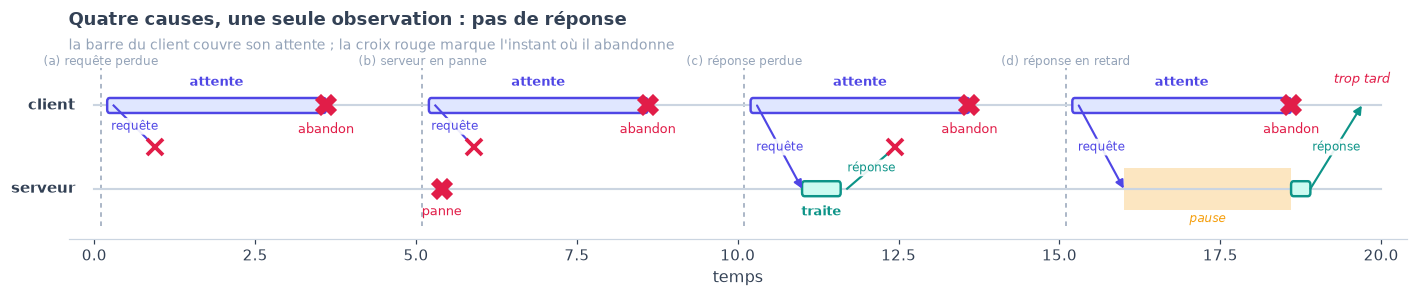

In [5]:
st = SpaceTime(["client", "serveur"], t_max=20, width=13, title="Quatre causes, une seule observation : pas de réponse",
               subtitle="la barre du client couvre son attente ; la croix rouge marque l'instant où il abandonne")
T = 3.4
for k, (t0, lab) in enumerate([(0.2, "(a) requête perdue"), (5.2, "(b) serveur en panne"),
                               (10.2, "(c) réponse perdue"), (15.2, "(d) réponse en retard")]):
    st.vline(t0 - 0.1, lab)
    st.op("client", t0, t0 + T, "attente", color=INDIGO)
    st.event("client", t0 + T, "abandon", kind="crash", color=ROSE)
st.msg("client", 0.3, "serveur", 1.6, "requête", color=INDIGO, lost=True)
st.event("serveur", 5.4, "panne", kind="crash")
st.msg("client", 5.3, "serveur", 6.5, "requête", color=INDIGO, lost=True)
st.msg("client", 10.3, "serveur", 11.0, "requête", color=INDIGO)
st.op("serveur", 11.0, 11.6, "traite", color=TEAL, above=False)
st.msg("serveur", 11.7, "client", 13.2, "réponse", color=TEAL, lost=True)
st.msg("client", 15.3, "serveur", 16.0, "requête", color=INDIGO)
st.span("serveur", 16.0, 18.6, "pause", color=AMBER)
st.op("serveur", 18.6, 18.9, "", color=TEAL)
st.msg("serveur", 18.9, "client", 19.7, "réponse", color=TEAL)
st.note(19.7, "client", "trop tard", dy=0.32, color=ROSE)
st.show()

La seule parade générale est le **délai d'expiration** (timeout) : après un certain
temps, on cesse d'attendre et on suppose que la réponse ne viendra pas. Mais même alors,
on ignore si le destinataire a reçu la requête, et une requête encore en file peut être
livrée **après** qu'on a abandonné (cas (d)).

**Conséquence pratique : relancer peut dupliquer.** Si l'on relance une opération après
un délai dépassé, on risque de l'exécuter deux fois. Mesurons-le : un client envoie 2 000
opérations « ajouter 10 € », relance jusqu'à 3 fois après un délai, sur un réseau qui perd
10 % des messages. Le serveur compte combien de fois chaque opération est exécutée.

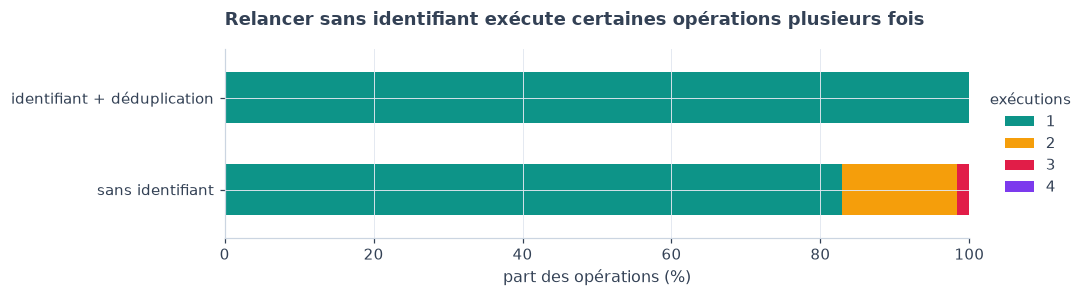

,sans identifiant,identifiant + déduplication
exécutions par opération,,
1,1658,2000
2,310,0
3,30,0
4,2,0


In [6]:
class Compteur(Node):
    def __init__(self, name, dedup):
        super().__init__(name)
        self.dedup, self.seen, self.execs = dedup, set(), {}

    def on_message(self, src, msg):
        op = msg[1]
        if not (self.dedup and op in self.seen):
            self.execs[op] = self.execs.get(op, 0) + 1
        self.seen.add(op)
        self.send(src, ("ok", op))


class ClientRelance(Node):
    def __init__(self, name, n_ops, timeout=3.0, max_tries=4):
        super().__init__(name)
        self.n_ops, self.timeout, self.max_tries = n_ops, timeout, max_tries
        self.acked = set()

    def on_start(self):
        for op in range(self.n_ops):
            self.set_timer(op * 0.5, self.essai, op, 1)

    def essai(self, op, k):
        if op in self.acked or k > self.max_tries:
            return
        self.send("serveur", ("ajouter 10", op))
        self.set_timer(self.timeout, self.essai, op, k + 1)

    def on_message(self, src, msg):
        self.acked.add(msg[1])


rows = {}
for dedup in (False, True):
    net = Network(seed=4, latency=(0.3, 1.8), drop=0.10)
    srv = net.add(Compteur("serveur", dedup))
    cli = net.add(ClientRelance("client", 2000))
    net.run()
    counts = pd.Series([srv.execs.get(op, 0) for op in range(2000)]).value_counts().sort_index()
    rows["sans identifiant" if not dedup else "identifiant + déduplication"] = counts
R = pd.DataFrame(rows).fillna(0).astype(int)
R.index.name = "exécutions par opération"
ax = (R / 20).T.plot.barh(stacked=True, figsize=(10, 2.8), color=[TEAL, AMBER, ROSE, VIOLET][:len(R)], width=0.55)
ax.set_xlabel("part des opérations (%)")
ax.set_title("Relancer sans identifiant exécute certaines opérations plusieurs fois")
ax.legend(title="exécutions", loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.tight_layout(); plt.show()
R

Sans précaution, environ une opération sur six (17 %) est exécutée **deux fois** ou plus
(la requête était passée, c'est la réponse qui s'était perdue ou attardée au-delà du
délai). Aucune n'est perdue ici : il faudrait que les quatre tentatives se perdent toutes,
ce qui arrive environ une fois sur dix mille.
Avec un **identifiant d'opération** que le serveur mémorise, chaque opération reçue est
exécutée exactement une fois : c'est l'idempotence, que l'on retrouvera aux chapitres
8 et 12.

> **À retenir.** Sur un réseau asynchrone, l'absence de réponse ne dit **rien** de ce
> qui s'est passé : requête perdue, nœud en panne ou en pause, réponse perdue ou en
> retard. Le délai d'expiration est la seule parade générale, et une relance doit être
> rendue idempotente (identifiant de requête) pour ne pas dupliquer l'opération.

## 3. Les pannes réseau en pratique (section *Network Faults in Practice*)

On construit des réseaux depuis des décennies, et ils ne sont toujours pas fiables. Les
études citées par le livre et les anecdotes abondent :

- dans un centre de données de taille moyenne, environ **12 pannes réseau par mois**,
  dont la moitié isolent une machine et l'autre moitié une baie entière ;
- la redondance du matériel réseau réduit moins les pannes qu'on l'espère, car elle ne
  protège pas des **erreurs humaines** (commutateurs mal configurés), cause majeure ;
- des liaisons longue distance coupées par des animaux (des requins mordent les câbles
  sous-marins, moins souvent depuis qu'ils sont mieux protégés) et par des humains ;
- des délais de paquets de **plus d'une minute** lors d'une reconfiguration du réseau
  après une mise à jour ratée d'un commutateur ; il faut donc supposer qu'un message peut
  être **retardé arbitrairement** ;
- des coupures **partielles** (A parle à B, B à C, mais pas A à C) et des liens qui ne
  marchent **que dans un sens** (une carte réseau qui perd tous les paquets entrants mais
  émet normalement) ;
- une brève interruption peut avoir des effets qui durent bien plus longtemps qu'elle.

Douze pannes par mois, c'est un processus de Poisson de taux 0,4 par jour : simulons
une année pour voir ce que cela représente.

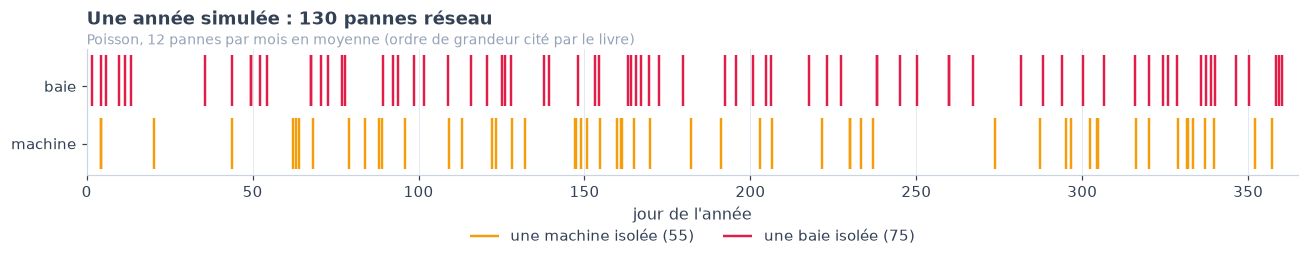

P(une semaine sans aucune panne réseau) = 6.1%


In [7]:
rate_day = 12 / 30
days = rng.exponential(1 / rate_day, 400).cumsum()
days = days[days < 365]
kind = rng.random(days.size) < 0.5
fig, ax = plt.subplots(figsize=(12, 2.8))
ax.vlines(days[kind], 0.55, 1.45, color=AMBER, lw=1.6, label=f"une machine isolée ({kind.sum()})")
ax.vlines(days[~kind], 1.65, 2.55, color=ROSE, lw=1.6, label=f"une baie isolée ({(~kind).sum()})")
ax.set_yticks([1, 2]); ax.set_yticklabels(["machine", "baie"])
ax.set_xlim(0, 365); ax.set_xlabel("jour de l'année")
ax.grid(axis="y", visible=False)
ax.set_title(f"Une année simulée : {days.size} pannes réseau")
subtitle(ax, "Poisson, 12 pannes par mois en moyenne (ordre de grandeur cité par le livre)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=2)
plt.tight_layout(); plt.show()
p_semaine = np.exp(-rate_day * 7)
print(f"P(une semaine sans aucune panne réseau) = {p_semaine:.1%}")

Une semaine sans panne réseau est **l'exception** (6 %). Même si les pannes sont rares
dans votre environnement, le simple fait qu'elles **puissent** se produire impose au
logiciel de savoir y réagir.

**Coupures partielles et asymétriques.** Utilisons le détecteur par battements de cœur
du module (`ds.HeartbeatMember` : chaque nœud émet un battement par unité de temps et
soupçonne un pair qu'il n'a pas entendu depuis 3,5 unités) sur trois nœuds A, B, C, et
regardons **qui soupçonne qui** après dix unités de temps, dans trois situations.

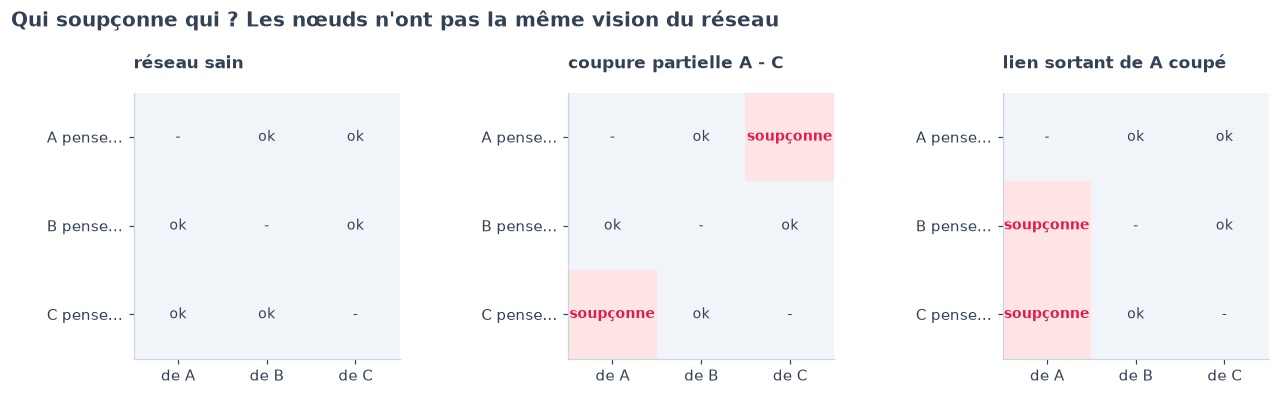

In [8]:
def suspicion(cut):
    net = Network(seed=2, latency=(0.2, 0.6))
    grp = ["A", "B", "C"]
    nodes = {g: net.add(ds.HeartbeatMember(g, grp, interval=1.0, timeout=3.5)) for g in grp}
    net.at(2.0, cut, net)
    net.run(until=12)
    return pd.DataFrame([[int(o in nodes[g].suspects) for o in grp] for g in grp], index=grp, columns=grp)

cas = {
    "réseau sain": lambda net: None,
    "coupure partielle A - C": lambda net: (net.block("A", "C"), net.block("C", "A")),
    "lien sortant de A coupé": lambda net: (net.block("A", "B"), net.block("A", "C")),
}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (nom, cut) in zip(axes, cas.items()):
    M = suspicion(cut)
    ax.imshow(M.values, cmap=ListedColormap([LIGHT[GRAY], LIGHT[ROSE]]), vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            txt = "-" if i == j else ("soupçonne" if M.values[i, j] else "ok")
            ax.text(j, i, txt, ha="center", va="center", fontsize=9,
                    color=ROSE if M.values[i, j] else SLATE, fontweight="bold" if M.values[i, j] else None)
    ax.set_xticks(range(3)); ax.set_xticklabels([f"de {x}" for x in "ABC"])
    ax.set_yticks(range(3)); ax.set_yticklabels([f"{x} pense..." for x in "ABC"])
    ax.grid(False); ax.set_title(nom, fontsize=11)
plt.suptitle("Qui soupçonne qui ? Les nœuds n'ont pas la même vision du réseau", x=0.01, ha="left",
             fontweight="bold", fontsize=13)
plt.tight_layout(); plt.show()

- Lors d'une **coupure partielle**, A et C se soupçonnent mutuellement, alors que B les
  voit tous deux en pleine forme : il n'existe pas de « vérité » partagée sur l'état du
  réseau.
- Si **seul le lien sortant** de A est coupé, B et C soupçonnent A, qui continue de
  recevoir leurs battements et ne soupçonne personne. A est vivant, se croit en bonne
  santé, et les autres vont le déclarer mort (le cours 4 reprend ce cauchemar avec un
  vote majoritaire).

Le terme **partition réseau** (network partition, netsplit) désigne une partie du réseau
coupée du reste ; ce n'est qu'un cas particulier de panne réseau. Attention à
l'homonymie : il n'a rien à voir avec le sharding des données, parfois appelé partitionnement (chapitre 7).

**Gérer n'est pas forcément tolérer.** Si le réseau est d'habitude fiable, afficher un
message d'erreur pendant l'incident peut suffire. En revanche, il faut **savoir** comment
le logiciel réagit et s'assurer qu'il se rétablit : un cluster mal conçu peut se bloquer
définitivement, même après le retour du réseau, ou même effacer des données. D'où l'intérêt
de **provoquer** des pannes réseau en test (injection de fautes, cours 6).

> **À retenir.** Les pannes réseau sont fréquentes, souvent humaines, parfois
> partielles ou à sens unique, et un message peut être retardé de plus d'une minute.
> Chaque nœud a sa propre vision, éventuellement fausse, de qui est joignable.

## 4. Détecter les fautes (section *Fault Detection*)

Beaucoup de systèmes doivent détecter automatiquement un nœud défaillant : un
**répartiteur de charge** doit cesser de lui envoyer des requêtes, et en réplication à
leader unique, si le leader tombe, un suiveur doit être promu (chapitre
6). Parfois, on reçoit un signal **explicite** :

- la machine répond mais aucun processus n'écoute le port (le processus a planté) : le
  système d'exploitation **refuse** la connexion TCP (paquet RST ou FIN) ;
- le processus a planté mais le système d'exploitation tourne encore : un script peut
  prévenir les autres nœuds sans attendre l'expiration d'un délai (HBase le fait) ;
- avec l'accès à l'interface d'administration des commutateurs, on peut détecter une
  panne de lien au niveau matériel (impossible via Internet ou dans un centre de données
  partagé) ;
- un routeur certain que l'adresse est injoignable peut répondre par un paquet ICMP
  *Destination Unreachable*, mais il n'a pas de pouvoir magique de détection.

Mesurons, sur la machine locale, ce que voit un client TCP dans quatre situations : port
fermé (processus mort), serveur bloqué qui accepte la connexion mais ne répond jamais,
serveur qui lit la requête puis plante, serveur sain.

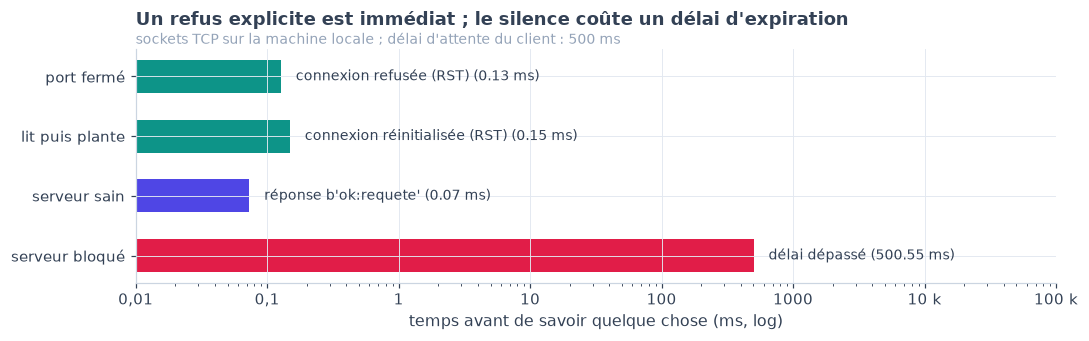

,situation,ce que voit le client,durée (ms)
0,port fermé,connexion refusée (RST),0.127
1,lit puis plante,connexion réinitialisée (RST),0.149
2,serveur sain,réponse b'ok:requete',0.073
3,serveur bloqué,délai dépassé,500.554


In [9]:
def serveur(mode, port_holder, ready):
    """Petit serveur local : `mode` = "bloque", "plante" ou "sain"."""
    srv = socket.socket()
    srv.setsockopt(socket.SOL_SOCKET, socket.SO_REUSEADDR, 1)
    srv.bind(("127.0.0.1", 0)); srv.listen(1)
    port_holder.append(srv.getsockname()[1]); ready.set()
    conn, _ = srv.accept()
    data = conn.recv(100)
    if mode == "sain":
        conn.sendall(b"ok:" + data)
    elif mode == "plante":
        conn.setsockopt(socket.SOL_SOCKET, socket.SO_LINGER, struct.pack("ii", 1, 0))  # RST
        conn.close()
    else:
        time.sleep(1.5)
        conn.close()
    srv.close()


def essai(mode, timeout=0.5):
    if mode == "port fermé":
        s = socket.socket(); s.bind(("127.0.0.1", 0)); port = s.getsockname()[1]; s.close()
    else:
        holder, ready = [], threading.Event()
        threading.Thread(target=serveur, args=({"serveur bloqué": "bloque", "lit puis plante": "plante",
                                                 "serveur sain": "sain"}[mode], holder, ready), daemon=True).start()
        ready.wait(); port = holder[0]
    t0 = time.perf_counter()
    c = socket.socket(); c.settimeout(timeout)
    try:
        c.connect(("127.0.0.1", port))
        c.sendall(b"requete")
        rep = c.recv(100)
        issue = f"réponse {rep!r}" if rep else "connexion fermée sans réponse"
    except ConnectionRefusedError:
        issue = "connexion refusée (RST)"
    except ConnectionResetError:
        issue = "connexion réinitialisée (RST)"
    except socket.timeout:
        issue = "délai dépassé"
    finally:
        c.close()
    return issue, (time.perf_counter() - t0) * 1e3


modes = ["port fermé", "lit puis plante", "serveur sain", "serveur bloqué"]
res = pd.DataFrame([dict(situation=m, **dict(zip(["ce que voit le client", "durée (ms)"], essai(m)))) for m in modes])
fig, ax = plt.subplots(figsize=(10, 3.2))
cols = [TEAL if "refus" in i or "réinit" in i else (ROSE if "délai" in i else INDIGO) for i in res["ce que voit le client"]]
ax.barh(res.situation[::-1], res["durée (ms)"][::-1], color=cols[::-1], height=0.55)
for y, (v, i) in enumerate(zip(res["durée (ms)"][::-1], res["ce que voit le client"][::-1])):
    ax.text(v * 1.3, y, f"{i} ({v:.2f} ms)", va="center", fontsize=9)
ax.set_xscale("log"); plain_log_axis(ax, "x")
ax.set_xlim(0.01, 1e5); ax.set_xlabel("temps avant de savoir quelque chose (ms, log)")
ax.set_title("Un refus explicite est immédiat ; le silence coûte un délai d'expiration")
subtitle(ax, "sockets TCP sur la machine locale ; délai d'attente du client : 500 ms")
plt.tight_layout(); plt.show()
res.round(3)

Les signaux explicites arrivent en une fraction de milliseconde, mais **on ne peut pas
compter sur eux** : ils supposent que la machine distante (ou un routeur) soit encore
capable de répondre. Remarquez aussi le cas « lit puis plante » : le client apprend que la
connexion est rompue, mais **pas** si sa requête a été traitée avant le plantage. En
général, il faut supposer qu'on ne recevra **aucune** réponse : on relance quelques
fois, on attend un délai, et l'on finit par déclarer le nœud mort.

Ce délai impose un compromis entre deux erreurs, que le cours 2 quantifie :

- trop **court**, il déclare morts des nœuds simplement lents (faux positifs) ;
- trop **long**, il fait attendre inutilement quand le nœud est vraiment mort.

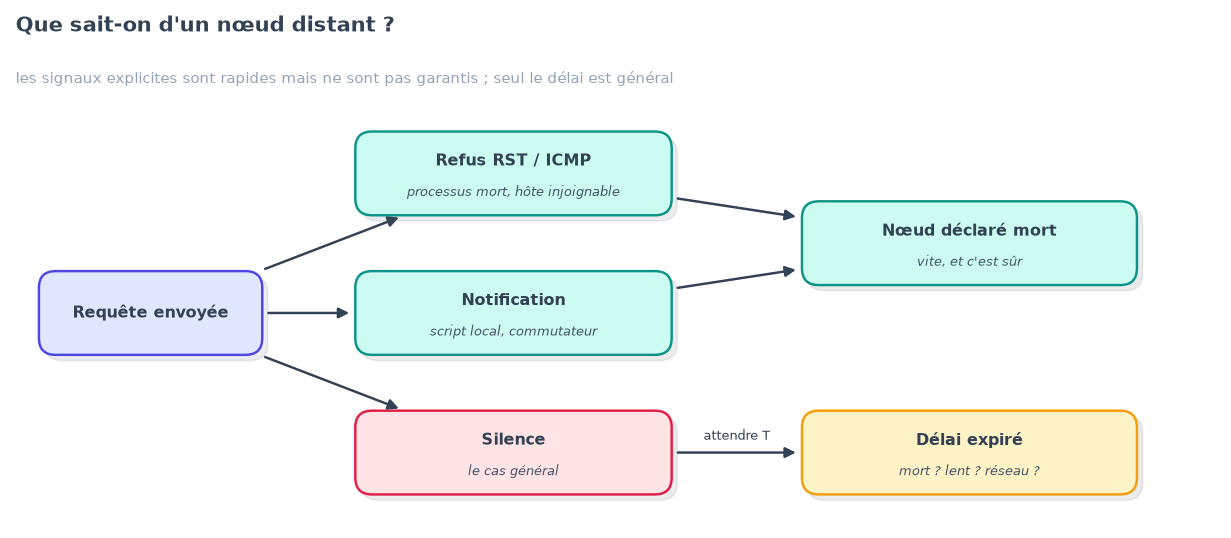

In [10]:
d = Diagram(13, 4.6, title="Que sait-on d'un nœud distant ?",
            subtitle="les signaux explicites sont rapides mais ne sont pas garantis ; seul le délai est général")
d.box("q", 1.5, 2.3, "Requête envoyée", color=INDIGO, w=2.4)
d.box("rst", 5.4, 3.8, "Refus RST / ICMP", sub="processus mort, hôte injoignable", color=TEAL, w=3.4)
d.box("notif", 5.4, 2.3, "Notification", sub="script local, commutateur", color=TEAL, w=3.4)
d.box("rien", 5.4, 0.8, "Silence", sub="le cas général", color=ROSE, w=3.4)
d.box("mort", 10.3, 3.05, "Nœud déclaré mort", sub="vite, et c'est sûr", color=TEAL, w=3.6)
d.box("to", 10.3, 0.8, "Délai expiré", sub="mort ? lent ? réseau ?", color=AMBER, w=3.6)
for b in ("rst", "notif", "rien"):
    d.arrow("q", b)
d.arrow("rst", "mort"); d.arrow("notif", "mort")
d.arrow("rien", "to", "attendre T")
d.show()

> **À retenir.** Un refus de connexion ou une notification permettent de conclure vite,
> mais ils ne sont pas garantis. Le mécanisme général de détection est le délai
> d'expiration, qui ne distingue pas un nœud mort d'un nœud lent ou d'un réseau
> défaillant.

## 5. Les limites de TCP : un accusé de réception n'est pas une réponse (section *The Limitations of TCP*)

Un paquet réseau fait au plus quelques kilo-octets ; pour envoyer des messages plus gros,
les applications utilisent presque toujours **TCP**, qui découpe un flux d'octets en
paquets et le reconstitue à l'arrivée (ce qui suit vaut aussi pour QUIC, SCTP et d'autres
protocoles de transport). TCP est dit « fiable » parce qu'il :

- détecte et **retransmet** les paquets perdus ;
- remet dans l'**ordre** les paquets arrivés dans le désordre ;
- détecte les paquets corrompus par une **somme de contrôle** simple (cours 5) ;
- adapte son débit pour ne surcharger ni le réseau ni le destinataire (contrôle de
  congestion et de flux, contre-pression).

Mais écrire dans une socket ne fait que copier les données dans un **tampon** du système
d'exploitation. L'accusé de réception TCP signifie seulement que le **noyau** distant a
reçu les octets, pas que l'**application** les a traités.

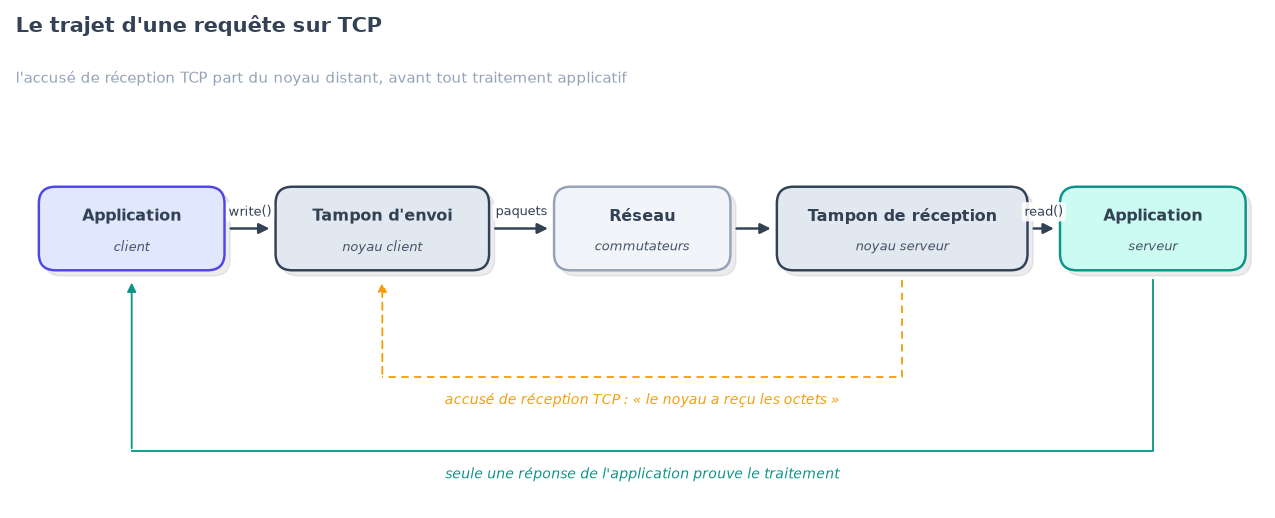

In [11]:
d = Diagram(13.5, 4.4, title="Le trajet d'une requête sur TCP",
            subtitle="l'accusé de réception TCP part du noyau distant, avant tout traitement applicatif")
d.box("app1", 1.3, 3.0, "Application", sub="client", color=INDIGO, w=2.0)
d.box("buf1", 4.0, 3.0, "Tampon d'envoi", sub="noyau client", color=SLATE, w=2.3)
d.box("net", 6.8, 3.0, "Réseau", sub="commutateurs", color=GRAY, w=1.9)
d.box("buf2", 9.6, 3.0, "Tampon de réception", sub="noyau serveur", color=SLATE, w=2.7)
d.box("app2", 12.3, 3.0, "Application", sub="serveur", color=TEAL, w=2.0)
d.arrow("app1", "buf1", "write()")
d.arrow("buf1", "net", "paquets")
d.arrow("net", "buf2")
d.arrow("buf2", "app2", "read()")
d.line([(9.6, 2.45), (9.6, 1.4), (4.0, 1.4), (4.0, 2.45)], color=AMBER, style="dashed")
d.note(6.8, 1.15, "accusé de réception TCP : « le noyau a reçu les octets »", color=AMBER)
d.line([(12.3, 2.45), (12.3, 0.6), (1.3, 0.6), (1.3, 2.45)], color=TEAL, style="solid")
d.note(6.8, 0.35, "seule une réponse de l'application prouve le traitement", color=TEAL)
d.show()

Vérifions-le avec de vraies sockets locales. Le client envoie 20 requêtes encadrées par
leur longueur (un en-tête de 4 octets puis le message, comme le font HTTP et la plupart
des protocoles RPC du chapitre 5). Le serveur en traite 3, puis « plante ».

In [12]:
def serveur_fragile(port_holder, ready, traites):
    srv = socket.socket(); srv.setsockopt(socket.SOL_SOCKET, socket.SO_REUSEADDR, 1)
    srv.bind(("127.0.0.1", 0)); srv.listen(1)
    port_holder.append(srv.getsockname()[1]); ready.set()
    conn, _ = srv.accept()
    f = conn.makefile("rb")
    for _ in range(3):
        n = struct.unpack("!I", f.read(4))[0]
        traites.append(f.read(n).decode())
        time.sleep(0.05)
    conn.setsockopt(socket.SOL_SOCKET, socket.SO_LINGER, struct.pack("ii", 1, 0))
    f.close(); conn.close(); srv.close()                 # plantage : le reste est perdu


holder, ready, traites = [], threading.Event(), []
th = threading.Thread(target=serveur_fragile, args=(holder, ready, traites), daemon=True)
th.start(); ready.wait()
c = socket.create_connection(("127.0.0.1", holder[0]))
envoyees = 0
for i in range(20):
    msg = f"requête {i}".encode()
    c.sendall(struct.pack("!I", len(msg)) + msg)        # aucune erreur : les octets vont au tampon
    envoyees += 1
th.join()
try:
    c.recv(10)
    suite = "fermeture propre"
except ConnectionResetError:
    suite = "connexion réinitialisée"
c.close()
print(f"sendall() réussis : {envoyees} ; requêtes traitées par le serveur : {len(traites)} {traites}")
print(f"ce que le client apprend ensuite : {suite}, sans savoir lesquelles ont été traitées")

sendall() réussis : 20 ; requêtes traitées par le serveur : 3 ['requête 0', 'requête 1', 'requête 2']
ce que le client apprend ensuite : connexion réinitialisée, sans savoir lesquelles ont été traitées


Les 20 envois ont « réussi » alors que seules 3 requêtes ont été traitées. Quand la
connexion se rompt, le client n'a **aucun moyen** de savoir combien de données
l'application distante a réellement traitées. Et la déduplication de TCP ne vaut **que
pour une connexion** : si le client se reconnecte et renvoie, des doublons apparaissent.
Le simulateur `ds.tcp_failure_outcomes` tire 2 000 ruptures au hasard et compare trois
politiques de reprise.

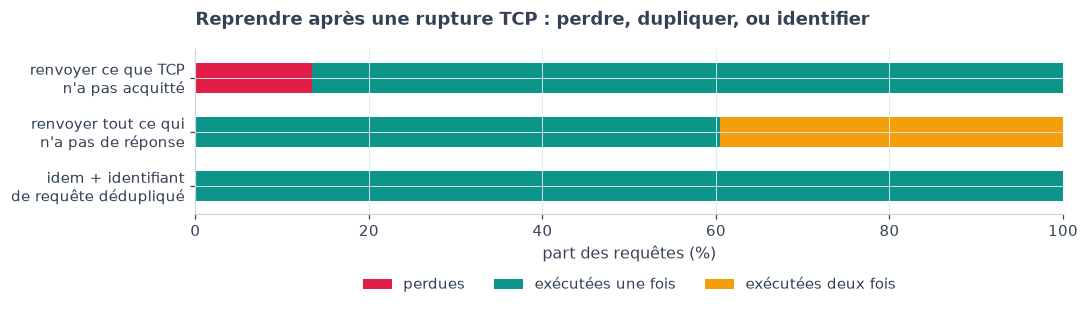

,perdues,une_fois,deux_fois
renvoyer ce que TCP\nn'a pas acquitté,13.4,86.6,0.0
renvoyer tout ce qui\nn'a pas de réponse,0.0,60.5,39.5
idem + identifiant\nde requête dédupliqué,0.0,100.0,0.0


In [13]:
pol = {"renvoyer ce que TCP\nn'a pas acquitté": "acquittements_tcp",
       "renvoyer tout ce qui\nn'a pas de réponse": "tout_renvoyer",
       "idem + identifiant\nde requête dédupliqué": "identifiants"}
O = pd.DataFrame({k: ds.tcp_failure_outcomes(policy=v) for k, v in pol.items()}).T * 100
ax = O[["perdues", "une_fois", "deux_fois"]].plot.barh(stacked=True, color=[ROSE, TEAL, AMBER], figsize=(10, 3.2), width=0.55)
ax.invert_yaxis()
ax.set_xlabel("part des requêtes (%)"); ax.set_xlim(0, 100)
ax.legend(["perdues", "exécutées une fois", "exécutées deux fois"], ncol=3, loc="upper center",
          bbox_to_anchor=(0.5, -0.3))
ax.set_title("Reprendre après une rupture TCP : perdre, dupliquer, ou identifier")
plt.tight_layout(); plt.show()
O.round(1)

Se fier aux acquittements TCP **perd** les requêtes reçues par le noyau mais jamais
traitées (le serveur a planté) ; tout renvoyer en **duplique** une part importante. Seule
une politique **de bout en bout** (identifiant de requête, réponse applicative) donne
l'effet « exactement une fois » : c'est l'argument de bout en bout de Saltzer, Reed et
Clark, qui reviendra au chapitre 13. TCP reste très utile (il transporte des
messages de toute taille et plusieurs requêtes par connexion), mais il ne dispense pas
l'application de raisonner sur les pannes.

> **À retenir.** TCP retransmet, réordonne et contrôle le débit, mais son accusé de
> réception ne prouve que l'arrivée dans le noyau distant. Après une rupture, on ignore
> ce qui a été traité ; seule une réponse de l'application, avec des requêtes
> identifiées, permet de reprendre sans perte ni doublon.

## Synthèse

- Une machine seule est (presque) déterministe : elle marche ou s'arrête. Un système
  distribué subit des **pannes partielles** non déterministes.
- Le réseau est **asynchrone** : un message peut se perdre ou être retardé
  arbitrairement, et l'émetteur ne peut pas distinguer les causes d'une absence de
  réponse. Relancer impose l'**idempotence**.
- Les pannes réseau sont **fréquentes**, parfois partielles ou asymétriques : chaque nœud
  a sa propre vision de l'état du système.
- Hormis quelques signaux explicites non garantis, la détection repose sur le **délai
  d'expiration**, compromis entre faux positifs et lenteur de détection (cours 2).
- TCP ne résout pas le problème : son accusé de réception n'est pas une réponse applicative.

Liens : la tolérance aux fautes et l'injection de fautes ont été introduites au
chapitre 2 ; la réplication (chapitre 6) et le consensus
(chapitre 10) sont précisément des algorithmes conçus pour fonctionner
malgré ces réseaux non fiables.